# Lab 2 — Returns and the stylised facts

**COMP0049 Market Microstructure · MSc Computational Finance, UCL · 2026–27**

In Lab 1 we learned to read a limit order book. In this lab we turn the book into a **price series**, the mid-price, and study the statistical properties of its returns. Using data, we reproduce the stylised facts of Chapter 4 of the lecture notes: fat tails, the absence of linear autocorrelation, volatility clustering and the long memory of the order flow.

**Learning outcomes.** By the end of the session you should be able to

1. build a mid-price series from LOB data and aggregate it into time bins (OHLC bars);
2. compute log returns at different sampling frequencies and explain how their behaviour changes with the scale;
3. show that high-frequency returns are **not Gaussian**: histogram, CCDF on log-log axes, excess kurtosis;
4. estimate and interpret **autocorrelation functions**: of returns, of absolute and squared returns (volatility clustering), and of trade signs (long memory of the order flow);
5. estimate the volatility at different sampling frequencies and read a **signature plot**.

**Theory.** Lecture notes Ch. 4 (§4.1 returns and volatility clustering, §4.2 autocorrelations, signature plot) and §8.2 (Lab 2 exercises Q1–Q9).

| Part | What we do | Lecture notes | 
|---|---|---|
| 0 | Setup, finding the data, the `cleaned_data` files | §8.2.1 |
| 1 | **Q1–Q2** Mid-price, spread, tick size: which kind of stock? | §2.5, §8.2 | 
| 2 | **Q3** Returns from binned mid-prices, at three frequencies | §4.1 | 
| 3 | **Q4–Q5** The distribution of returns: histogram, CCDF, kurtosis, aggregation | §4.1.1–4.1.3, §4.1.7 | 
| 4 | **Q6** Autocorrelation of returns and of absolute returns | §4.1.5–4.1.6, §4.2.4 | 
| 5 | **Q7** Volatility, the signature plot and the variogram | §4.2.1, §4.2.3 | 
| 6 | **Q8** Squared returns, volatility clustering and fat tails | §4.1.5, §4.2.4 |
| 7 | **Q9** The long memory of the order flow | §4.2.2 | 

## The data

We use one trading day, **3 January 2019**, for five NASDAQ stocks with very different tick sizes: **MSFT, FB, JNJ, TSLA and GOOG**.

The files are the `cleaned_data` versions of the LOBSTER files of Lab 1: the message file and the order book file glued side by side (the "one flat table" of Lab 1), with the time stamp already converted to a date and time. One row per event, 46 columns:

`DateTime, Event_Type, Order_ID, Size, Price, Direction, Ask_Price_Level_1, Ask_Volume_Level_1, Bid_Price_Level_1, Bid_Volume_Level_1, …, Bid_Volume_Level_10`

> **Two things to watch.**
> 1. The book prices (`Ask_Price_Level_k`, `Bid_Price_Level_k`) are in **dollars**, but the `Price` column of the event is still in LOBSTER units (dollars × 10,000).
> 2. `Direction` is LOBSTER's `TradeDirection`: the side of the **resting limit order**. The sign of a market order is $\epsilon = -\texttt{Direction}$ (Lab 1, §1.1).

**Where to put the files.** 

```
Stocks/
├── TSLA/
│   ├── cleaned_data/TSLA_2019-01-03_34200000_57600000_orderbook_10.csv
│   └── raw_data/   (the original LOBSTER message and orderbook files)
├── MSFT/ ...
```

Put the `Stocks` folder next to this notebook (or set `MY_STOCKS_DIR` below). 

---
# Part 0 — Setup

## 0.1 Libraries

On top of the Lab 1 stack (`numpy`, `pandas`, `matplotlib`) we use `scipy` and `statsmodels`. If an import fails: `pip install scipy statsmodels` and restart the kernel.

In [110]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy import stats
from scipy.special import erfc
import statsmodels.api as sm

print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {mpl.__version__}")

pandas 2.3.3 | numpy 2.3.5 | matplotlib 3.10.6


In [111]:
# Constants 
TICK        = 0.01            # NASDAQ tick size tau: one cent (book prices in the cleaned files are in dollars)
PRICE_SCALE = 10_000          # the 'Price' column of the event is still in LOBSTER units (dollars x 10,000)
EMPTY_LEVEL = 999_999         # LOBSTER's filler price for an empty level, in dollars (9,999,999,999 / 10,000)
RNG = np.random.default_rng(2026)   # one random generator, so that the shuffled tests below are reproducible

# Plot style (the same as in Lab 1) 
ACCENT, MUTED, LIGHT, INK = "#2a78d6", "#898781", "#c3c2b7", "#0b0b0b"
GAUSS_COLOR = "#898781"                                   # Gaussian references: always grey, dashed
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 100, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": LIGHT, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})


def hours(index):
    # Time of day in hours (9.5 = 09:30) for a DatetimeIndex.
    return (index - index.normalize()) / pd.Timedelta(hours=1)


def time_axis(ax):
    # Format an x-axis expressed in hours-of-day as 09:30 ... 16:00.
    ax.set_xlim(9.5, 16)
    ax.set_xticks(range(10, 17))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda h, _: f"{int(h):02d}:{int(round((h % 1) * 60)):02d}"))
    ax.set_xlabel("Time of day (New York)")


def seconds_label(s):
    # 10 -> '10s', 60 -> '1min', 300 -> '5min'
    return f"{s // 60:g}min" if s >= 60 and s % 60 == 0 else f"{s:g}s"

## 0.2 Where is the data?

As in the lecture notes (§8.2.1, Step 2) we find the files with `glob`. The cell looks for the `Stocks` folder in a few standard places and lists the stocks that have a `cleaned_data` file.

In [112]:
MY_STOCKS_DIR = None    # e.g. Path("/full/path/to/Stocks") if the search below fails

here = Path.cwd()
candidates = [
    MY_STOCKS_DIR,
    here / "Stocks",
    here / "ReturnsDemo25" / "Stocks",
    here / "Microstructure demos" / "ReturnsDemo25" / "Stocks",
    here.parent / "ReturnsDemo25" / "Stocks",
    Path.home() / "Desktop" / "COMP0049" / "Stocks",
]
STOCKS_DIR = next((Path(p) for p in candidates
                   if p is not None and Path(p).is_dir() and glob.glob(f"{p}/*/cleaned_data/*.csv")), None)
if STOCKS_DIR is None:
    raise FileNotFoundError("No 'Stocks/<TICKER>/cleaned_data/*.csv' files found. Put the Stocks folder next to "
                            "this notebook, or set MY_STOCKS_DIR above.")

AVAILABLE = sorted(Path(f).parts[-3] for f in glob.glob(f"{STOCKS_DIR}/*/cleaned_data/*.csv"))
try:
    shown = STOCKS_DIR.relative_to(here)
except ValueError:
    shown = STOCKS_DIR
print(f"Stocks folder: {shown}")
print(f"Stocks with cleaned data: {AVAILABLE}")

Stocks folder: /Users/parth/Desktop/COMP0049/Stocks
Stocks with cleaned data: ['FB', 'GOOG', 'JNJ', 'MSFT', 'TSLA']


## 0.3 A first look at one file (§8.2.1, Steps 2–3)

We start with **TSLA**, as in the lecture notes. Before computing anything, look at what you have.

In [113]:
stock = "TSLA"
all_files = glob.glob(f"{STOCKS_DIR}/{stock}/cleaned_data/*.csv")
print(all_files)

df = pd.read_csv(all_files[0])        # one file = one trading day
print(df.shape)
df.head()

['/Users/parth/Desktop/COMP0049/Stocks/TSLA/cleaned_data/TSLA_2019-01-03_34200000_57600000_orderbook_10.csv']
(546078, 46)


,DateTime,Event_Type,Order_ID,Size,Price,Direction,Ask_Price_Level_1,Ask_Volume_Level_1,Bid_Price_Level_1,Bid_Volume_Level_1,...,Bid_Price_Level_8,Bid_Volume_Level_8,Ask_Price_Level_9,Ask_Volume_Level_9,Bid_Price_Level_9,Bid_Volume_Level_9,Ask_Price_Level_10,Ask_Volume_Level_10,Bid_Price_Level_10,Bid_Volume_Level_10
0,2019-01-03 09:30:00:708346,1,13167276.0,50,3065300.0,1,307.2,1000,307.00,244,...,306.06,12,308.12,200,306.0,135,308.24,100,305.60,1
1,2019-01-03 09:30:00:716851,4,NaN,25,3070000.0,1,307.2,1000,307.00,219,...,306.06,12,308.12,200,306.0,135,308.24,100,305.60,1
2,2019-01-03 09:30:00:716886,4,NaN,128,3070000.0,1,307.2,1000,307.00,91,...,306.06,12,308.12,200,306.0,135,308.24,100,305.60,1
3,2019-01-03 09:30:00:716934,5,NaN,230,3070000.0,-1,307.2,1000,306.99,10,...,306.00,135,308.12,200,305.6,1,308.24,100,305.50,11
4,2019-01-03 09:30:00:716974,3,13167276.0,50,3065300.0,1,307.2,1000,306.99,10,...,305.60,1,308.12,200,305.5,11,308.24,100,305.41,8


In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 546078 entries, 0 to 546077
Data columns (total 46 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   DateTime             546078 non-null  object 
 1   Event_Type           546078 non-null  int64  
 2   Order_ID             526173 non-null  float64
 3   Size                 546078 non-null  int64  
 4   Price                546078 non-null  float64
 5   Direction            546078 non-null  int64  
 6   Ask_Price_Level_1    546078 non-null  float64
 7   Ask_Volume_Level_1   546078 non-null  int64  
 8   Bid_Price_Level_1    546078 non-null  float64
 9   Bid_Volume_Level_1   546078 non-null  int64  
 10  Ask_Price_Level_2    546078 non-null  float64
 11  Ask_Volume_Level_2   546078 non-null  int64  
 12  Bid_Price_Level_2    546078 non-null  float64
 13  Bid_Volume_Level_2   546078 non-null  int64  
 14  Ask_Price_Level_3    546078 non-null  float64
 15  Ask_Volume_Level_

`DateTime` arrives as a **string** (`object`). Time-based operations need `datetime64` values. The format codes are `%Y` year, `%m` month, `%d` day, `%H` hour, `%M` minute, `%S` second, `%f` microsecond.

In [115]:
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%Y-%m-%d %H:%M:%S:%f")

## 0.4 A loader for all the stocks

For this lab we only need the event columns and the first two levels of the book. Reading only those columns (`usecols`) makes the loading lighter: the MSFT file alone has more than two million rows. `load_stock` also

- sets `DateTime` as the index (needed for resampling),
- keeps the events between `start` and `end` (by default the whole session, 09:30–16:00),
- adds the mid-price and the spread.

In [7]:
COLUMNS = ["DateTime", "Event_Type", "Size", "Price", "Direction",
           "Ask_Price_Level_1", "Ask_Volume_Level_1", "Bid_Price_Level_1", "Bid_Volume_Level_1",
           "Ask_Price_Level_2", "Bid_Price_Level_2"]


def load_stock(stock, start="09:30", end="16:00"):
    # Load the cleaned LOBSTER file of one stock, indexed by time, with mid-price and spread (in dollars).
    path = sorted(glob.glob(f"{STOCKS_DIR}/{stock}/cleaned_data/*.csv"))[0]
    data = pd.read_csv(path, usecols=COLUMNS)
    data["DateTime"] = pd.to_datetime(data["DateTime"], format="%Y-%m-%d %H:%M:%S:%f")
    data = data.set_index("DateTime").between_time(start, end, inclusive="left")
    # level 2 can be empty (LOBSTER filler price): mark it as missing rather than keep a huge number
    for col in ("Ask_Price_Level_2", "Bid_Price_Level_2"):
        data[col] = data[col].where(data[col].abs() < EMPTY_LEVEL)
    data["MidPrice"] = (data["Ask_Price_Level_1"] + data["Bid_Price_Level_1"]) / 2
    data["Spread"] = data["Ask_Price_Level_1"] - data["Bid_Price_Level_1"]
    return data


del df                                       # the full 46 column table is no longer needed
STOCKS = [s for s in ["MSFT", "FB", "JNJ", "TSLA", "GOOG"] if s in AVAILABLE] + \
         [s for s in AVAILABLE if s not in ["MSFT", "FB", "JNJ", "TSLA", "GOOG"]]
data = {s: load_stock(s) for s in STOCKS}
for s in STOCKS:
    print(f"{s:5s} {len(data[s]):>10,} events | {data[s].index[0].time()} -> {data[s].index[-1].time()}")

MSFT   2,040,060 events | 09:30:00.627361 -> 15:59:59.999448
FB       783,829 events | 09:30:00.690212 -> 15:59:59.999613
JNJ      301,460 events | 09:30:00.327721 -> 15:59:59.925588
TSLA     546,078 events | 09:30:00.708346 -> 15:59:59.923772
GOOG   1,391,516 events | 09:30:00.038374 -> 15:59:59.994797


---
# Part 1 — Mid-price and stock properties

## Q1. Mid-price

> Compute the mid-price $x(t) = \tfrac12 [a(t) + b(t)]$ and add it as a column.

`load_stock` has already done it (`MidPrice`); here it is for TSLA, together with its path through the day. With half a million events, plotting every point is slow and useless for the eye: we plot the last value in each second.

In [8]:
data["TSLA"]["MidPrice"] = (data["TSLA"]["Bid_Price_Level_1"] + data["TSLA"]["Ask_Price_Level_1"]) / 2
data["MSFT"]["MidPrice"] = (data["MSFT"]["Bid_Price_Level_1"] + data["MSFT"]["Ask_Price_Level_1"]) / 2
data["FB"]["MidPrice"] = (data["FB"]["Bid_Price_Level_1"] + data["FB"]["Ask_Price_Level_1"]) / 2
data["JNJ"]["MidPrice"] = (data["JNJ"]["Bid_Price_Level_1"] + data["JNJ"]["Ask_Price_Level_1"]) / 2
data["GOOG"]["MidPrice"] = (data["GOOG"]["Bid_Price_Level_1"] + data["GOOG"]["Ask_Price_Level_1"]) / 2

In [9]:
data["TSLA"][["Bid_Price_Level_1", "Ask_Price_Level_1", "MidPrice"]].head()

,Bid_Price_Level_1,Ask_Price_Level_1,MidPrice
DateTime,,,
2019-01-03 09:30:00.708346,307.00,307.2,307.100
2019-01-03 09:30:00.716851,307.00,307.2,307.100
2019-01-03 09:30:00.716886,307.00,307.2,307.100
2019-01-03 09:30:00.716934,306.99,307.2,307.095
2019-01-03 09:30:00.716974,306.99,307.2,307.095


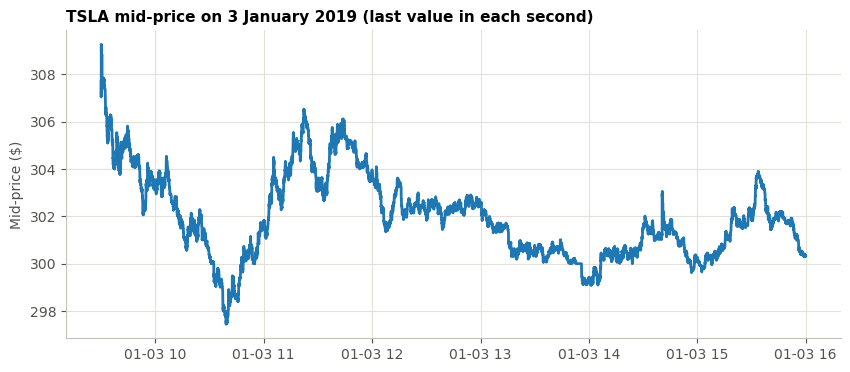

In [10]:
plt.figure(1)
plt.plot(data["TSLA"]["MidPrice"].resample("1s").last().ffill())
plt.ylabel("Mid-price ($)")
plt.title("TSLA mid-price on 3 January 2019 (last value in each second)")
plt.show()

## Q2. Stock properties

> Compute (i) the average spread and (ii) the empirical tick size, and use them to classify the stock as small-, medium- or large-tick (§2.5).

The **empirical tick size** is the smallest price difference we ever observe in the book: between the two best quotes, or between two adjacent levels on the same side. Prices are stored as floating-point numbers, so 0.01 may appear as 0.00999999…; we round to a tenth of a cent before taking the minimum.

The criteria of §2.5 (used in Lab 1): relative tick $\tilde\tau = \tau / x$ above 2–3 bp means large tick, below 1 bp small tick; an average spread below 1.5 ticks means large tick, above 3 ticks small tick, medium in between.

In [11]:
for ticker in data:
    diffs = []
    for i in range(1,3):
        for j in range(1,len(data[ticker].index)):
            diffs.append(data[ticker][f"Ask_Price_Level_{i}"].iloc[j] - data[ticker][f"Ask_Price_Level_{i}"].iloc[j-1])
    
    diffs = np.array(diffs)
    tick_size = np.round(np.min(diffs[diffs > 0]), 3)

    avg_spread = np.round(np.mean(data[ticker]["Ask_Price_Level_1"] - data[ticker]["Bid_Price_Level_1"]),3)

    print(ticker + " average spread", avg_spread)
    print(ticker + " empirical tick size", tick_size)

    if avg_spread >= 3*tick_size:
        print(ticker + " is a small-tick stock")
    if 1.5*tick_size < avg_spread < 3*tick_size:
        print(ticker + " is a medium-tick stock")
    if avg_spread <= 1.5*tick_size:
        print(ticker + " is a large-tick stock")
    print()

MSFT average spread 0.013
MSFT empirical tick size 0.01
MSFT is a large-tick stock

FB average spread 0.046
FB empirical tick size 0.01
FB is a small-tick stock

JNJ average spread 0.054
JNJ empirical tick size 0.01
JNJ is a small-tick stock

TSLA average spread 0.182
TSLA empirical tick size 0.01
TSLA is a small-tick stock

GOOG average spread 1.05
GOOG empirical tick size 0.01
GOOG is a small-tick stock



---
# Part 2 — Returns from binned mid-prices

## Q3. Bins, OHLC bars and log returns

> Aggregate the mid-price into fixed time bins (1 s, 10 s, 1 min) and compute the Open/High/Low/Close within each bin. Using the Close of each bin, form log returns $r_t = \log C_t - \log C_{t-\Delta t}$. Plot the return series at each frequency and discuss how the behaviour changes with the scale.

**Why bins?** The mid-price is recorded at irregular times (every event), and most events do not change it. To talk about "the return over 10 seconds" we need a regular grid: we cut the day into bins of length $\Delta t$ and summarise the mid-price inside each bin by four numbers, **O**pen (first value), **H**igh, **L**ow and **C**lose (last value).

a) Build the bars with a `for` loop over the groups; 
b) `pandas` does the same in one line with `resample(...).ohlc()`. 
Let us check on 10-second bins that the two agree.

In [12]:
def ohlc(ticker, frequency):
    ohlc_ticker_frequency = data[ticker]["MidPrice"].resample(frequency).ohlc()
    return ohlc_ticker_frequency

In [13]:
ohlc("TSLA", "10s").head()

,open,high,low,close
DateTime,,,,
2019-01-03 09:30:00,307.100,309.275,306.960,308.860
2019-01-03 09:30:10,308.860,309.045,308.685,308.765
2019-01-03 09:30:20,308.765,308.940,308.655,308.780
2019-01-03 09:30:30,308.780,308.780,307.040,307.510
2019-01-03 09:30:40,307.510,307.685,307.460,307.685


**From bars to returns.** We use the Close of each bin. Two choices deserve a word:

- **Empty bins.** At 1 s some bins contain no event at all. The mid-price did not change during that second, so we carry the last price forward (`ffill`): the return over an empty bin is zero.
- **Log returns.** $r_t = \log C_t - \log C_{t-\Delta t} = \log(C_t / C_{t-\Delta t})$. They add up over time and, for small moves, are practically equal to the percentage change. We quote them in **basis points** (1 bp = 0.01%).

*(The lecture notes, eq. 4.1, define the binned price as the **average** mid-price in the bin rather than the last one. Averaging smooths the series and introduces spurious autocorrelation between consecutive returns; with the Close we keep the returns of a genuine sampled price.)*

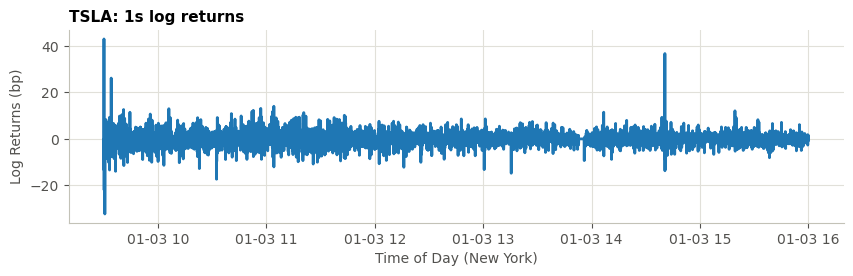

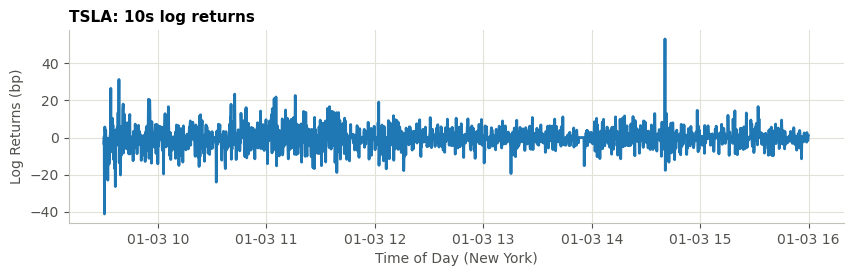

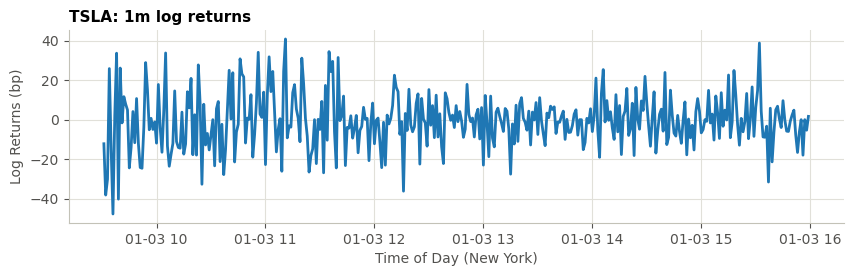

In [91]:
def log_returns(ticker, frequency):
    close = ohlc(ticker, frequency)["close"].ffill().dropna()
    return 1e4*np.log(close).diff() 

def lin_returns(ticker, frequency):
    close = ohlc(ticker, frequency)["close"].ffill().dropna()
    return 1e4*close.pct_change() 

plt.figure(figsize=(10, 2.5))
plt.plot(log_returns("TSLA", "1s"))
plt.ylabel('Log Returns (bp)')
plt.xlabel('Time of Day (New York)')
plt.title('TSLA: 1s log returns')
plt.show()

plt.figure(figsize=(10, 2.5))
plt.plot(log_returns("TSLA", "10s"))
plt.ylabel('Log Returns (bp)')
plt.xlabel('Time of Day (New York)')
plt.title('TSLA: 10s log returns')
plt.show()

plt.figure(figsize=(10, 2.5))
plt.plot(log_returns("TSLA", "60s"))
plt.ylabel('Log Returns (bp)')
plt.xlabel('Time of Day (New York)')
plt.title('TSLA: 1m log returns')
plt.show()

---
# Part 3 — The distribution of returns

## Q4. Histogram, Gaussian and CCDF

> Histogram the log returns for each bin size and compare with a Gaussian of the same mean and variance. Then plot the empirical CCDF on log-log axes (§4.1.2) — the tail behaviour is far easier to judge there than in a histogram.

On a **linear** vertical axis every histogram looks more or less bell-shaped: the tails, where the interesting differences are, are invisible. On a **logarithmic** vertical axis a Gaussian is a downward parabola, and fat tails stand out immediately.

In [92]:
import scipy 
from scipy.stats import norm

In [93]:
def mean_log(ticker, frequency):
    mean = np.mean(log_returns(ticker, frequency))
    return mean

def mean_lin(ticker, frequency):
    mean = np.mean(lin_returns(ticker, frequency))
    return mean

In [94]:
def std_log(ticker, frequency):
    std = np.std(log_returns(ticker, frequency))
    return std

def std_lin(ticker, frequency):
    std = np.std(lin_returns(ticker, frequency))
    return std

In [95]:
x1 = np.linspace(np.min(log_returns("TSLA", "1s")), np.max(log_returns("TSLA", "1s")), 400)
x2 = np.linspace(np.min(log_returns("TSLA", "10s")), np.max(log_returns("TSLA", "10s")), 400)
x3 = np.linspace(np.min(log_returns("TSLA", "60s")), np.max(log_returns("TSLA", "60s")), 400)

In [96]:
y1 = np.linspace(np.min(lin_returns("TSLA", "1s")), np.max(lin_returns("TSLA", "1s")), 400)
y2 = np.linspace(np.min(lin_returns("TSLA", "10s")), np.max(lin_returns("TSLA", "10s")), 400)
y3 = np.linspace(np.min(log_returns("TSLA", "60s")), np.max(lin_returns("TSLA", "60s")), 400)

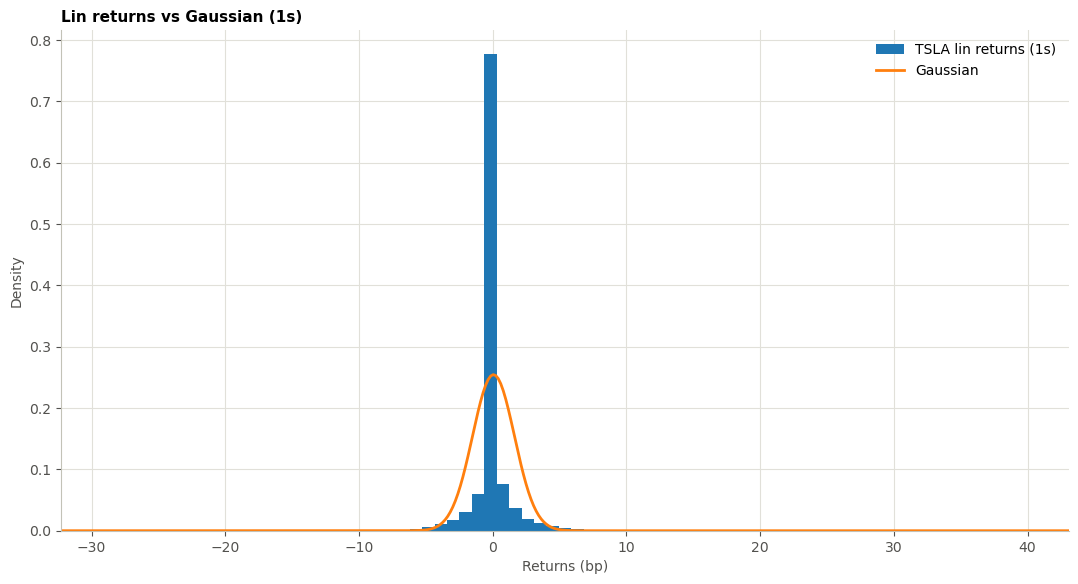

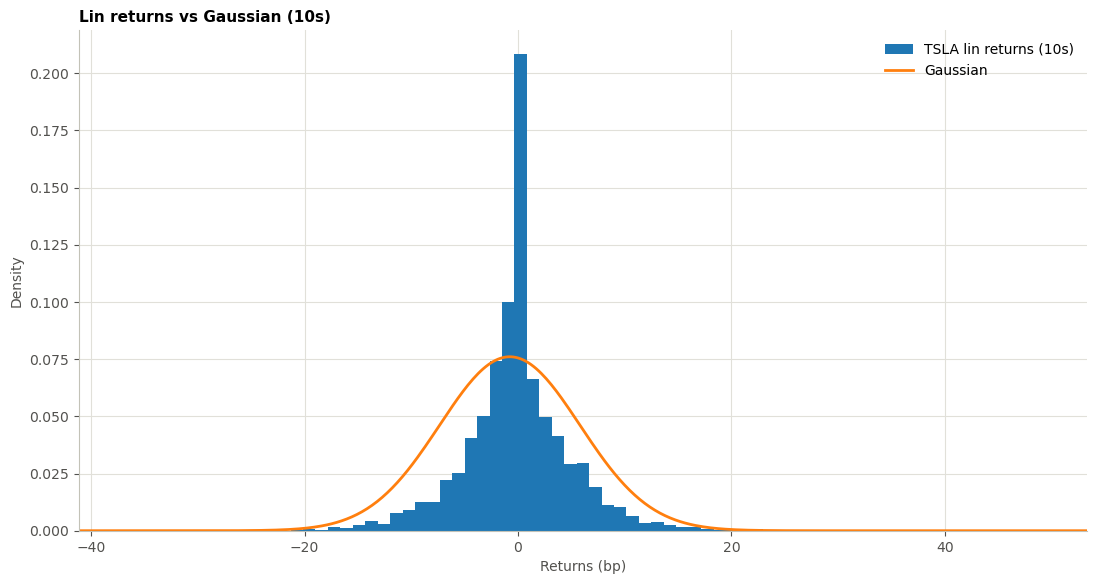

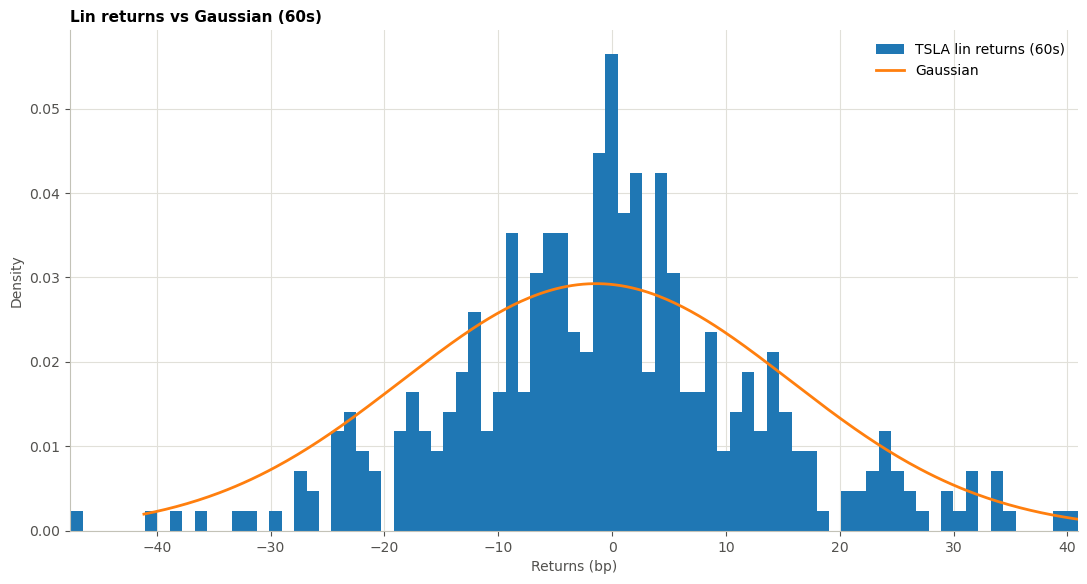

In [105]:
plt.figure(figsize=(13, 6.5))
plt.hist(lin_returns("TSLA", "1s"), bins=81, density=True, label = 'TSLA lin returns (1s)')
plt.plot(y1,norm(mean("TSLA", "1s"), std("TSLA", "1s")).pdf(x), label = 'Gaussian')
plt.xlim(np.min(lin_returns("TSLA", "1s")), np.max(lin_returns("TSLA", "1s")))
plt.xlabel('Returns (bp)')
plt.ylabel('Density')
plt.title('Lin returns vs Gaussian (1s)')
plt.legend()
plt.show()

plt.figure(figsize=(13, 6.5))
plt.hist(lin_returns("TSLA", "10s"), bins=81, density=True, label = 'TSLA lin returns (10s)')
plt.plot(y2,norm(mean("TSLA", "10s"), std("TSLA", "10s")).pdf(x), label = 'Gaussian')
plt.xlim(np.min(lin_returns("TSLA", "10s")), np.max(lin_returns("TSLA", "10s")))
plt.xlabel('Returns (bp)')
plt.ylabel('Density')
plt.title('Lin returns vs Gaussian (10s)')
plt.legend()
plt.show()

plt.figure(figsize=(13, 6.5))
plt.hist(lin_returns("TSLA", "60s"), bins=81, density=True, label = 'TSLA lin returns (60s)')
plt.plot(y2,norm(mean("TSLA", "60s"), std("TSLA", "60s")).pdf(x), label = 'Gaussian')
plt.xlim(np.min(lin_returns("TSLA", "60s")), np.max(lin_returns("TSLA", "60s")))
plt.xlabel('Returns (bp)')
plt.ylabel('Density')
plt.title('Lin returns vs Gaussian (60s)')
plt.legend()
plt.show()

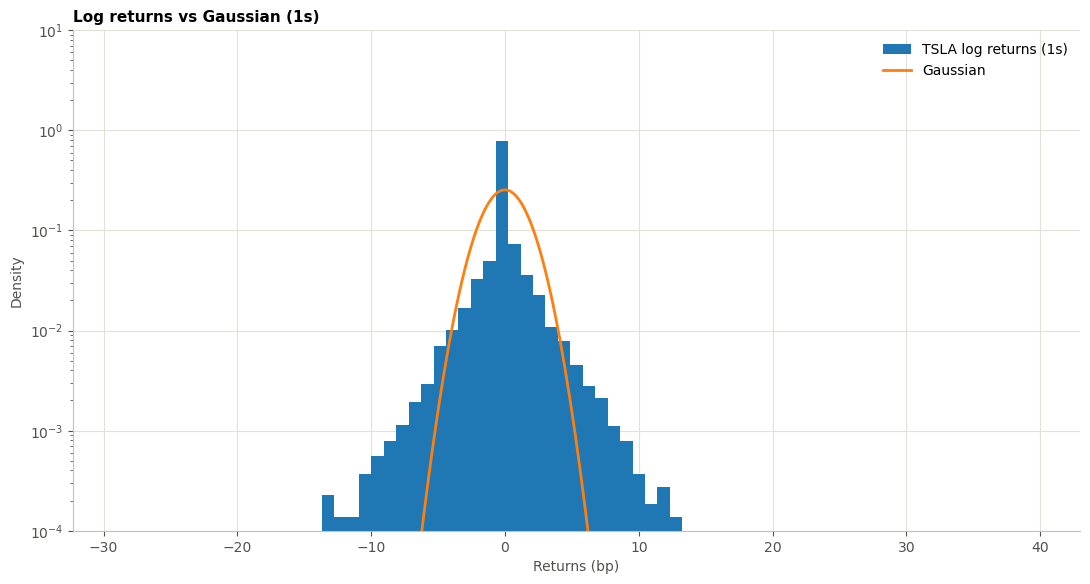

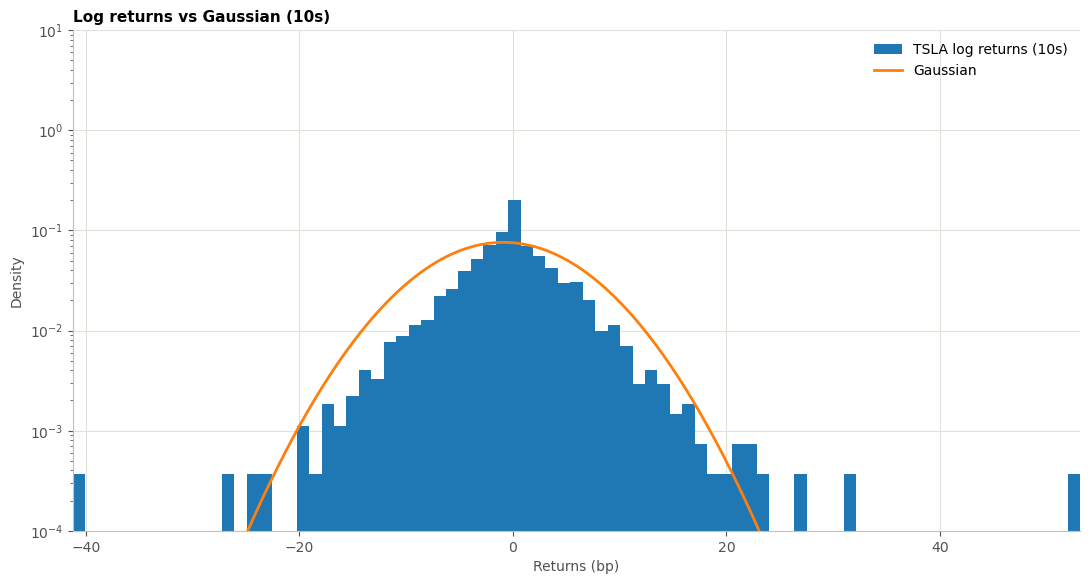

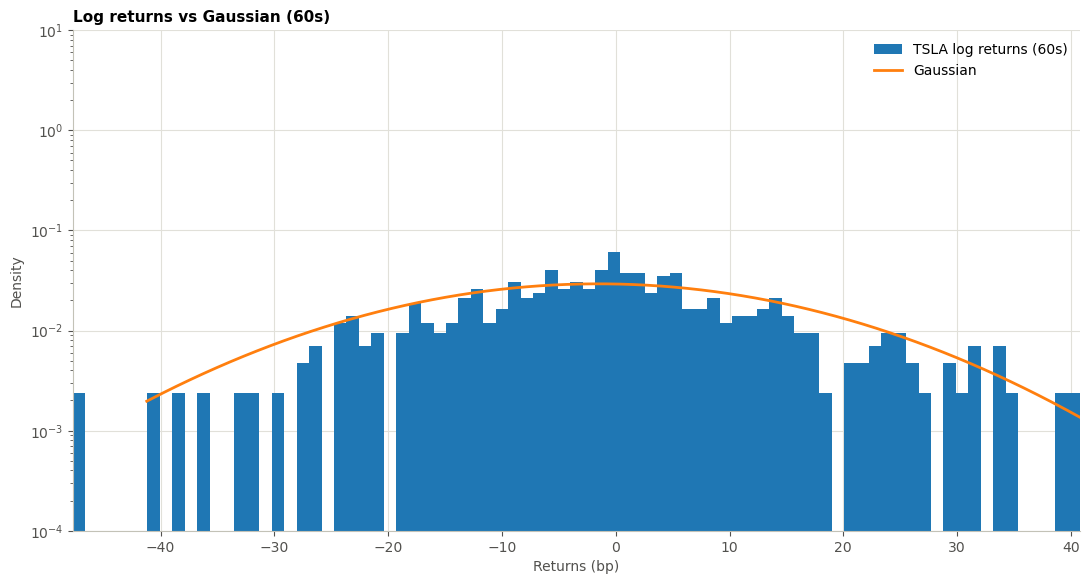

In [108]:
plt.figure(figsize=(13, 6.5))
plt.hist(log_returns("TSLA", "1s"), bins=81, density=True, label = 'TSLA log returns (1s)')
plt.plot(x1,norm(mean("TSLA", "1s"), std("TSLA", "1s")).pdf(x), label = 'Gaussian')
plt.xlim(np.min(log_returns("TSLA", "1s")), np.max(log_returns("TSLA", "1s")))
plt.ylim(1e-4, 10)
plt.xlabel('Returns (bp)')
plt.ylabel('Density')
plt.yscale('log')
plt.title('Log returns vs Gaussian (1s)')
plt.legend()
plt.show()

plt.figure(figsize=(13, 6.5))
plt.hist(log_returns("TSLA", "10s"), bins=81, density=True, label = 'TSLA log returns (10s)')
plt.plot(x2,norm(mean("TSLA", "10s"), std("TSLA", "10s")).pdf(x), label = 'Gaussian')
plt.xlim(np.min(log_returns("TSLA", "10s")), np.max(log_returns("TSLA", "10s")))
plt.ylim(1e-4, 10)
plt.xlabel('Returns (bp)')
plt.ylabel('Density')
plt.yscale('log')
plt.title('Log returns vs Gaussian (10s)')
plt.legend()
plt.show()

plt.figure(figsize=(13, 6.5))
plt.hist(log_returns("TSLA", "60s"), bins=81, density=True, label = 'TSLA log returns (60s)')
plt.plot(x2,norm(mean("TSLA", "60s"), std("TSLA", "60s")).pdf(x), label = 'Gaussian')
plt.xlim(np.min(log_returns("TSLA", "60s")), np.max(log_returns("TSLA", "60s")))
plt.ylim(1e-4, 10)
plt.xlabel('Returns (bp)')
plt.ylabel('Density')
plt.yscale('log')
plt.title('Log returns vs Gaussian (60s)')
plt.legend()
plt.show()